# Fig. 6e: weights of the model of sorting accuracy for Kilosort 4 (biophysical, spontaneous, Neuropixels)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel e of the paper: the weights of the fractional regression (binomial GLM with logit link) that models the sorting accuracy of each ground truth neuron from its 21 biological features (same neurons, features and model as fig6c.ipynb). Source data and svg are saved in figures/8_source_data/fig6e/.

**method (the paper's model)**
* ground truth: first 10 minutes of the biophysical spontaneous simulation; sorting: Kilosort 4 (10 min); sorting accuracy = best agreement score (delta_time = 1.3 ms) with a sorted unit
* features: firing rate, synapse class, etype and layer (one-hot), distance to the nearest site (3D), SNR and spatial extent of the ground truth waveforms, exc_mini_frequency, dynamics_holding_current (`model_template` is dropped)
* the features are z-scored over the neurons: a weight is the change in the log-odds of the accuracy for an increase of one standard deviation of a feature
* the model is fitted on all neurons with a complete set of features (the 78 neurons without spikes have no waveform and are ignored by the fit); lasso setting of the paper's code (elastic net with alpha = 0, 100 iterations, tolerance 1e-10), then refitted for one iteration
* p-value of each weight: Wald test of the fitted model. Weights significantly different from 0 (p < 0.05) are in pink; stars: *: p < 0.05, **: p < 0.01, ***: p < 0.001

In [1]:
%load_ext autoreload
%autoreload 2
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "1"
import copy
import numpy as np
import pandas as pd
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.core.template_tools as ttools
from spikeinterface import extract_waveforms
from spikeinterface import qualitymetrics as qm
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
from src.nodes.metrics import metrics
from src.nodes.models.Fr import dataloader as fr_dataloader
from src.nodes.models.Fr.models import FrModel

# paths
RECORDING_PATH = "dataset/00_raw/recording_npx_spont/"
GT_PATH = "dataset/00_raw/ground_truth_npx_spont_10m"          # first 10 min
KS4_PATH = "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m/"

# parameters
FREQ_MIN = 300
REFERENCE = "global"
OPERATOR = "median"
MS_BEFORE = 3
MS_AFTER = 3
DURATION_SEC = 600
DT = 1.3
MAX_SPIKES_PER_UNIT = 500
SEED = 0
JOB_KWARGS = dict(n_jobs=16, chunk_duration="1s", progress_bar=False)

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Load the datasets

In [2]:
%%time

# recording (first 10 minutes, as for the sorting)
Recording = si.load_extractor(RECORDING_PATH)
Recording.set_property("location", Recording.get_property("location")[:, :2])
Recording = spre.highpass_filter(Recording, freq_min=FREQ_MIN)
Recording = spre.common_reference(Recording, reference=REFERENCE, operator=OPERATOR)
Recording = Recording.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))

# ground truth and sorting
SortingTrue = si.load_extractor(GT_PATH)
Sorting = si.load_extractor(KS4_PATH)
display(Recording)
display(SortingTrue)
display(Sorting)

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/spikeinterface/core/base.py:1079: UserWarning: Versions are not the same. This might lead to compatibility errors. Using spikeinterface==0.101.2 is recommended
  warnings.warn(


FrameSliceRecording: 384 channels - 40.0kHz - 1 segments - 24,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 34.33 GiB

NumpyFolderSorting: 1388 units - 1 segments - 40.0kHz

NumpyFolderSorting: 520 units - 1 segments - 40.0kHz

CPU times: user 5.83 ms, sys: 1.98 ms, total: 7.81 ms
Wall time: 7.59 ms


## Ground truth waveforms (in memory; sparse, 6 ms window)

In [3]:
%%time

We = extract_waveforms(Recording, SortingTrue, folder=None, mode="memory", sparse=True, ms_before=MS_BEFORE, ms_after=MS_AFTER,
                       max_spikes_per_unit=MAX_SPIKES_PER_UNIT, seed=SEED, **JOB_KWARGS)
display(We)

WaveformExtractor: 384 channels - 1388 units - 1 segments
  before:120 after:120 n_per_units:500 - sparse

CPU times: user 8.18 s, sys: 13.4 s, total: 21.6 s
Wall time: 3min 31s


## Dataset: predictors (ground truth neuron features) and target (sorting accuracy)

In [4]:
%%time

dataset = pd.DataFrame()

# firing rate
n_spikes = SortingTrue.get_total_num_spikes()
dataset["firing_rate"] = [n_spikes[unit] / DURATION_SEC for unit in n_spikes]

# synapse class
dataset = fr_dataloader.set_synapse_class(dataset, SortingTrue)

# etype (one-hot)
dataset = pd.merge(dataset, pd.get_dummies(SortingTrue.get_property("etype")), left_index=True, right_index=True)

# layer (one-hot)
layers = np.array(["2/3" if (w == "2") or (w == "3") else w for w in SortingTrue.get_property("layer")])
layer_df = pd.get_dummies(layers)
layer_df.columns = ["layer_1", "layer_23", "layer_4", "layer_5", "layer_6"]
dataset = pd.merge(dataset, layer_df, left_index=True, right_index=True)

# 3D site coordinates (the recording's "location" property; get_probe().contact_positions has a null z for this recording)
Rec = si.load_extractor(RECORDING_PATH)
channel_coord = Rec.get_property("location")
channel_ids = Rec.get_channel_ids()

# distance to the nearest site (um)
unit_xyz = np.c_[SortingTrue.get_property("x"), SortingTrue.get_property("y"), SortingTrue.get_property("z")]
dataset["distance"] = [np.min(np.linalg.norm(channel_coord - xyz, axis=1)) for xyz in unit_xyz]

# signal-to-noise ratio
snrs = qm.compute_snrs(We, peak_sign="neg", peak_mode="extremum", unit_ids=We.sorting.unit_ids)
dataset["snr"] = snrs.values()

# spike spatial extent
max_chids = ttools.get_template_extremum_channel(We, peak_sign="neg")
dataset["spatial_extent"] = [
    metrics.get_spatial_spread(We, unit, max_chids, channel_ids, channel_coord)["spatial_spread"] for unit in We.unit_ids
]

# other features
dataset["exc_mini_frequency"] = SortingTrue.get_property("exc_mini_frequency")
dataset["dynamics_holding_current"] = SortingTrue.get_property("dynamics_holding_current")

# target: sorting accuracy
dataset["sorting_accuracy"] = fr_dataloader.get_accuracy(Sorting, SortingTrue, delta_time=DT).values
dataset.index = SortingTrue.unit_ids

# curate: drop units with an infinite feature. Units without spikes in the 10 minutes have no waveform: their snr and
# spatial_extent are missing. As in the paper's pipeline they stay in the dataset used for cross-validation (the model
# fits ignore rows with a missing feature), and are removed for the figure
dataset = dataset.drop(index=dataset.index[dataset.sum(axis=1) == np.inf])
predictors = dataset.columns.drop(["sorting_accuracy"])
print("neurons:", len(dataset), "| with a missing feature:", int(dataset.isna().any(axis=1).sum()), "| predictors:", len(predictors))

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/spikeinterface/core/base.py:1079: UserWarning: Versions are not the same. This might lead to compatibility errors. Using spikeinterface==0.101.2 is recommended
  warnings.warn(


neurons: 1388 | with a missing feature: 78 | predictors: 21
CPU times: user 3.63 s, sys: 352 ms, total: 3.98 s
Wall time: 3.98 s


## Model weights (paper's model, fitted on all neurons)

In [5]:
%%time

frmodel = FrModel(predictors, "sorting_accuracy", order=1)
fullresults = frmodel.evaluate_on_full_dataset(dataset=dataset, scale_data=True, regularization="elastic_net",
                                               maxiter=100, cnvrg_tol=1e-10, verbose=False)
fullmodel = fullresults["metric_data"]["model"]
print("neurons used by the fit:", int(fullmodel.nobs))

2026-11-02 13:04:27,278 - root - utils.py - evaluate_on_full_dataset - INFO - Z-scoring the dataset features...


2026-11-02 13:04:27,281 - root - utils.py - evaluate_on_full_dataset - INFO - Done Z-scoring.


2026-11-02 13:04:27,642 - root - utils.py - evaluate_on_full_dataset - INFO - Done training the model.


neurons used by the fit: 1310
CPU times: user 369 ms, sys: 0 ns, total: 369 ms
Wall time: 369 ms


## Source data: weight and significance of each feature

In [6]:
LABELS = {"exc_mini_frequency": "exc_mini_freq", "dynamics_holding_current": "holding_current"}    # as in the paper's figure
df = pd.DataFrame({"feature": [LABELS.get(f, f) for f in fullmodel.params.index.drop("Intercept")],
                   "weight": fullmodel.params.drop("Intercept").values, "std_error": fullmodel.bse.drop("Intercept").values,
                   "p_value": fullmodel.pvalues.drop("Intercept").values})
df["significance"] = np.select([df["p_value"] < 0.001, df["p_value"] < 0.01, df["p_value"] < 0.05], ["***", "**", "*"], "")
df["n_neurons"] = int(fullmodel.nobs)
df = df.sort_values("weight").reset_index(drop=True)
display(df.round(4))

,feature,weight,std_error,p_value,significance,n_neurons
0,distance,-1.4595,0.1468,0.0000,***,1310
1,layer_6,-0.3665,0.1411,0.0094,**,1310
2,dNAC,-0.2712,0.3973,0.4949,,1310
3,snr,-0.2042,0.1457,0.1610,,1310
4,cNAC,-0.1913,0.1176,0.1038,,1310
5,bAC,-0.1540,0.2328,0.5082,,1310
6,exc_mini_freq,-0.1397,0.2028,0.4912,,1310
7,layer_23,-0.1215,0.1391,0.3822,,1310
8,cSTUT,-0.1084,0.2470,0.6606,,1310
9,layer_1,-0.0981,0.0967,0.3103,,1310


In [7]:
PINK = "#f4667d"     # colour of the significant weights in the paper figure (RGB 244, 102, 125)

def plot_source_data(df: pd.DataFrame):
    """Weights of the z-scored features (bars); weights significantly different from 0 (p < 0.05) in pink; weights and stars
    written to the right of the bars"""

    fig, ax = plt.subplots(1, 1, figsize=(2.3, 2.6))
    d = df.sort_values("weight").reset_index(drop=True)
    sig = d["significance"].fillna("")
    ypos = np.arange(len(d))
    ax.barh(ypos, d["weight"], color=np.where(sig != "", PINK, "k"), height=0.8)
    for y_, (w, s) in enumerate(zip(d["weight"], sig)):
        ax.text(1.1, y_, f"{w:.2f}", va="center", ha="left")
        ax.text(1.95, y_, s, va="center", ha="left")

    # aesthetics
    ax.set_yticks(ypos); ax.set_yticklabels(d["feature"])
    ax.invert_yaxis()
    ax.set_xlim(-1.7, 2.4); ax.set_xticks([-1, 0, 1, 2])
    ax.set_xlabel("Weights of z-scored features"); ax.set_ylabel("Unit features")
    ax.set_title("Spontaneous model", fontweight="bold", fontsize=6.5)
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.spines["left"].set_position(("axes", -0.05))
    fig.text(0.5, 1.0, "ks4 sorting accuracy biases for unit features (Biophy, NPX)", ha="center", va="bottom", fontweight="bold", fontsize=6.5)
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 142 ms, sys: 8.89 ms, total: 151 ms
Wall time: 151 ms


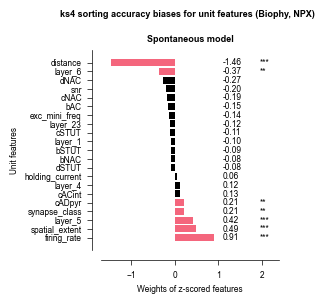

In [8]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig6e", exist_ok=True)
plt.savefig("figures/8_source_data/fig6e/fig6e.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig6e/fig6e.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 24.1 ms, sys: 89 µs, total: 24.2 ms
Wall time: 24.2 ms


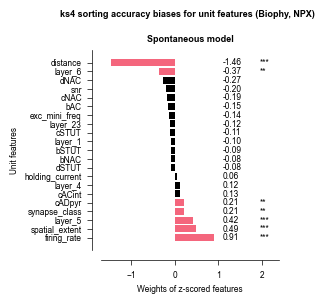

In [9]:
%%time

df = pd.read_excel("figures/8_source_data/fig6e/fig6e.xlsx")
fig, ax = plot_source_data(df)